# 04 · Graph evaluation: discovered vs expert graph

**Objective.** Compare the graph discovered by PCMCI+ (notebook 03) with the expert graph of the coolant subsystem.

**How temporal links become static edges** (the mapping used here and in notebook 03)

| PCMCI+ output | Static edge |
|---|---|
| lagged link `X(t-τ) → Y(t)`, τ ≥ 1, X ≠ Y | directed `X → Y` (oriented by time order) |
| contemporaneous link oriented by PCMCI+ (`-->`) | directed `X → Y` (oriented by conditional-independence rules, not by timestamps) |
| contemporaneous link `o-o` or `x-x` | undirected `X — Y`; **never oriented by guesswork** |
| autodependency `X(t-τ) → X(t)` | ignored (no self-loops in the expert graph) |
| several lags for one pair | one edge; the lags are kept as information |
| relations from several regimes | kept when found in ≥ 50% of the regimes where the pair was testable |

**Metrics.**
- Skeleton precision, recall and F1 ignore direction.
- Directed precision, recall and F1 count an edge only with the right direction; undirected edges never count as correct directions.
- SHD counts missing and extra adjacencies plus wrong or unresolved marks on shared adjacencies.
- Orientation accuracy is measured over shared adjacencies that were oriented.

Results are reported over **all pairs** and over **testable pairs only**, the pairs some regime could actually test. Lagged and contemporaneous evidence are reported separately.

**Caveat.** Agreement with the expert graph is agreement with expert knowledge, not proof of the true causal structure. Settings in notebook 03 were fixed before this comparison. Choosing among the sensitivity variants by their score here would tune on the reference and bias the evaluation, so the variants are reported, not selected.

In [1]:
import json

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
SUBSYSTEM = 'coolant'
N_RANDOM = 2000
SEED = 0

In [2]:
# expert reference and discovered graphs from notebook 03
expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
types = {n: ('Alarm' if expert.nodes[n]['kind'] == 'Alarm' else 'Binary') for n in NODES}
tables = data.RESULTS_DIR / 'tables'
edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
pairs = pd.read_csv(tables / f'03_{SUBSYSTEM}_pairs.csv')
graphs = {gid: cd.edges_to_graph(g, NODES) for gid, g in edges.groupby('graph_id')}
discovered = graphs['discovered']

# pairs that at least one regime could test
testable = [frozenset((a, b)) for a, b, d in zip(pairs.a, pairs.b, pairs.decision) if d != 'untestable']
untestable_expert = [(u, v) for u, v in expert.edges() if frozenset((u, v)) not in set(testable)]
print(f'expert edges: {expert.number_of_edges()}, testable pairs: {len(testable)} of {len(pairs)}')
print('expert edges that no regime could test:', untestable_expert)

expert edges: 10, testable pairs: 61 of 105
expert edges that no regime could test: []


## 1. Expert vs discovered graph

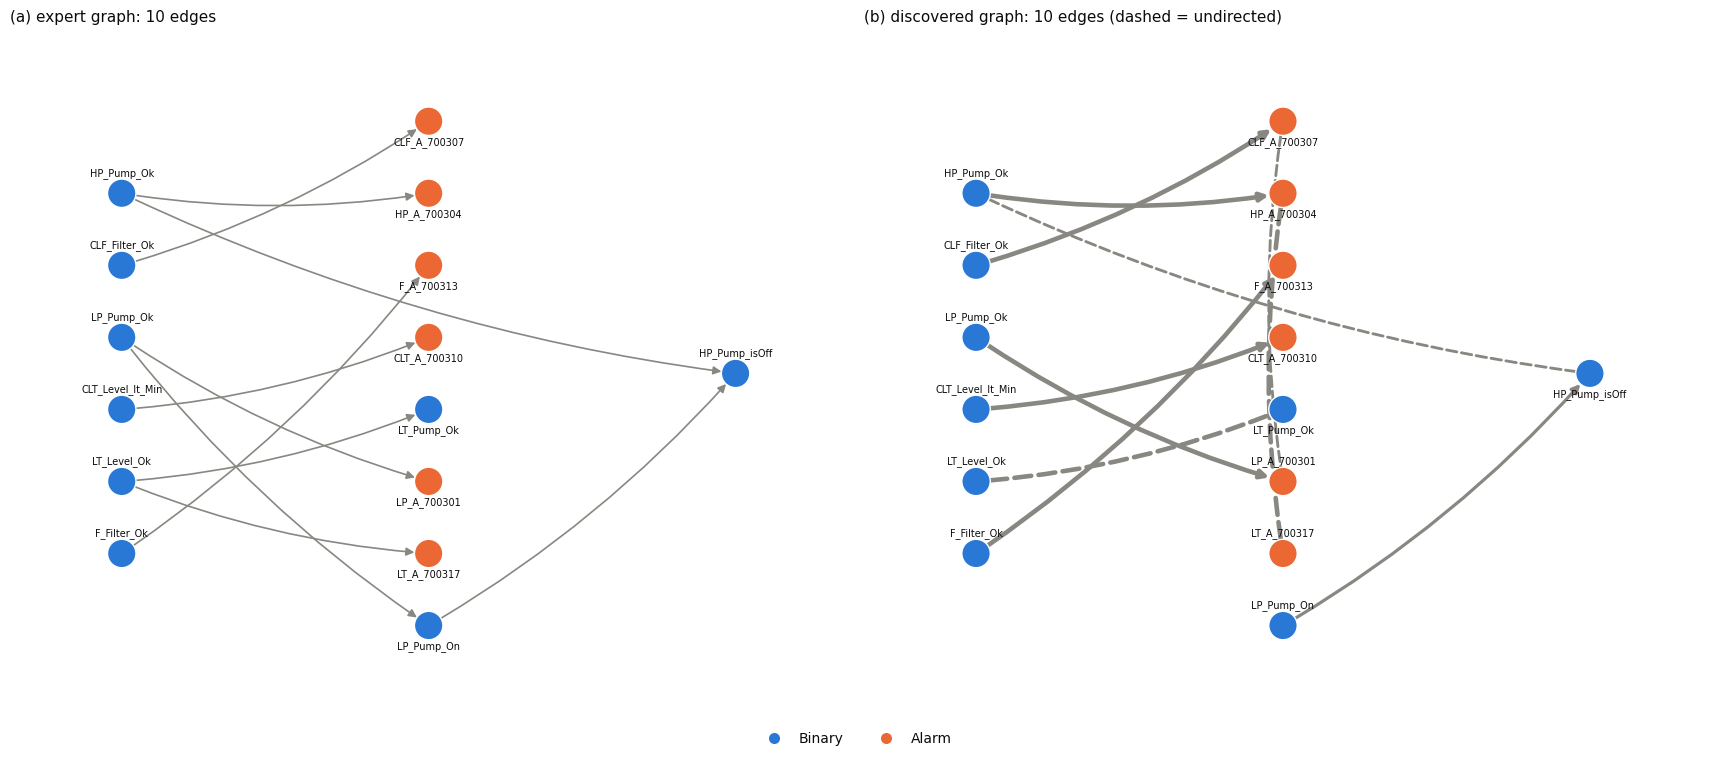

In [3]:
# figure 1: expert graph and discovered graph on the same layout
layout = ev.graph_layout(expert)
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), layout='constrained')
ev.draw_graph(expert, axes[0], node_types=types, pos=layout, title=f'(a) expert graph: {expert.number_of_edges()} edges')
ev.draw_graph(discovered, axes[1], node_types=types, pos=layout, width_by_support=True,
              title=f'(b) discovered graph: {discovered.number_of_edges()} edges (dashed = undirected)')
fig.legend(handles=ev.type_legend_handles(['Binary', 'Alarm']), loc='outside lower center', ncol=2)
ev.save_figure(fig, f'04_{SUBSYSTEM}_expert_vs_discovered')
plt.show()

In [4]:
# edge-by-edge comparison
comparison = ge.edge_comparison_table(discovered, expert)
lag_info = {frozenset((a, b)): l for a, b, l in zip(pairs.a, pairs.b, pairs.lags)}
comparison['lags_steps'] = [lag_info.get(frozenset((a, b)), '') for a, b in zip(comparison.a, comparison.b)]
comparison['testable'] = [frozenset((a, b)) in set(testable) for a, b in zip(comparison.a, comparison.b)]
ev.save_table(comparison, f'04_{SUBSYSTEM}_edge_comparison')
comparison.sort_values(['outcome', 'a'])

,a,b,expert,discovered,outcome,lags_steps,testable
0,CLF_A_700307,CLF_Filter_Ok,CLF_Filter_Ok->CLF_A_700307,CLF_Filter_Ok->CLF_A_700307,correct direction,"[10, 11]",True
2,CLT_A_700310,CLT_Level_lt_Min,CLT_Level_lt_Min->CLT_A_700310,CLT_Level_lt_Min->CLT_A_700310,correct direction,[2],True
3,F_A_700313,F_Filter_Ok,F_Filter_Ok->F_A_700313,F_Filter_Ok->F_A_700313,correct direction,[10],True
4,HP_A_700304,HP_Pump_Ok,HP_Pump_Ok->HP_A_700304,HP_Pump_Ok->HP_A_700304,correct direction,[0],True
7,HP_Pump_isOff,LP_Pump_On,LP_Pump_On->HP_Pump_isOff,LP_Pump_On->HP_Pump_isOff,correct direction,"[0, 1, 2, 16, 17]",True
8,LP_A_700301,LP_Pump_Ok,LP_Pump_Ok->LP_A_700301,LP_Pump_Ok->LP_A_700301,correct direction,[0],True
1,CLF_A_700307,LP_A_700301,None,undirected,extra,[0],True
5,HP_A_700304,LT_A_700317,None,undirected,extra,[0],True
9,LP_Pump_Ok,LP_Pump_On,LP_Pump_Ok->LP_Pump_On,None,missed,[],True
10,LT_A_700317,LT_Level_Ok,LT_Level_Ok->LT_A_700317,None,missed,[],True


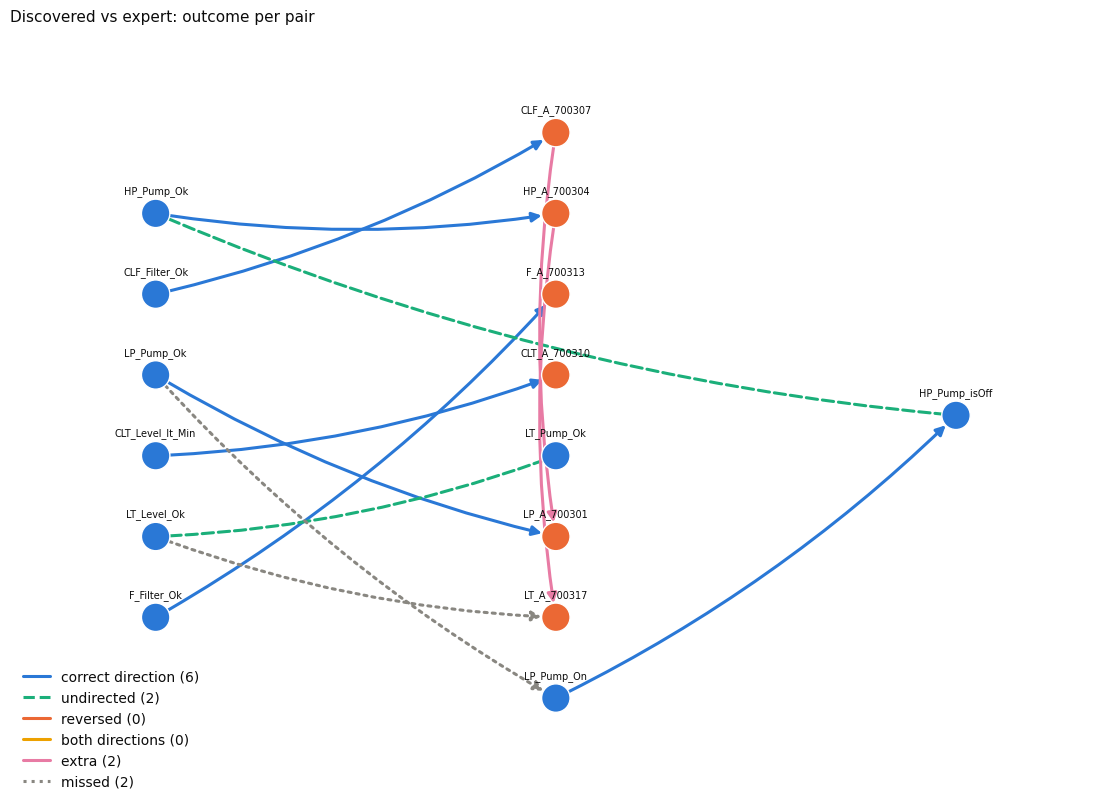

In [5]:
# figure 2: comparison graph (colour = outcome of each pair)
outcome_style = {
    'correct direction': (ev.COLORS[0], 'solid'),
    'undirected': (ev.COLORS[2], 'dashed'),
    'reversed': (ev.COLORS[1], 'solid'),
    'both directions': (ev.COLORS[3], 'solid'),
    'extra': (ev.COLORS[4], 'solid'),
    'missed': (ev.INK['muted'], 'dotted'),
}
fig, ax = plt.subplots(figsize=(11, 8), layout='constrained')
g_nodes = nx.DiGraph()
g_nodes.add_nodes_from(NODES)
ev.draw_graph(g_nodes, ax, node_types=types, pos=layout, title='Discovered vs expert: outcome per pair')
for outcome, (color, style) in outcome_style.items():
    rows = comparison[comparison.outcome == outcome]
    edgelist = []
    for row in rows.itertuples(index=False):
        mark = row.expert if outcome == 'missed' else row.discovered
        if isinstance(mark, str) and '->' in mark:
            edgelist.append(tuple(mark.split('->')))
        else:
            edgelist.append((row.a, row.b))
    if edgelist:
        nx.draw_networkx_edges(g_nodes, layout, edgelist=edgelist, ax=ax, edge_color=color, style=style, width=2.2,
                               arrows=True, arrowsize=14, node_size=420, connectionstyle='arc3,rad=0.08',
                               arrowstyle='-' if outcome == 'undirected' else '-|>')
handles = [plt.Line2D([], [], color=c, linestyle=s, linewidth=2.2, label=f'{o} ({int((comparison.outcome == o).sum())})')
           for o, (c, s) in outcome_style.items()]
ax.legend(handles=handles, loc='lower left')
ev.save_figure(fig, f'04_{SUBSYSTEM}_comparison_graph')
plt.show()

## 2. Metrics against the expert graph and against chance

The random reference draws graphs with the same number of edges as the discovered graph, uniformly over the same pairs and with random directions. It gives the chance level of each metric.

In [6]:
# metrics on all pairs and on testable pairs, with random references
rows = []
reference_draws = {}
for scope, pair_set in (('all pairs', None), ('testable pairs', testable)):
    metrics = ge.compare_graphs(discovered, expert, pairs=pair_set)
    rows.append({'graph': 'discovered', 'scope': scope, **metrics})
    n_edges = metrics['n_pred_edges']
    draws = ge.random_reference(expert, n_edges, n_draws=N_RANDOM, seed=SEED, pairs=pair_set)
    reference_draws[scope] = draws
    rows.append({'graph': 'random (mean)', 'scope': scope, **draws.mean().to_dict()})
metric_table = pd.DataFrame(rows)
ev.save_table(metric_table, f'04_{SUBSYSTEM}_metrics')
metric_cols = ['graph', 'scope', 'n_pred_edges', 'n_true_edges', 'skeleton_precision', 'skeleton_recall', 'skeleton_f1',
               'directed_precision', 'directed_recall', 'directed_f1', 'shd', 'orientation_accuracy']
metric_table[metric_cols].round(3)

,graph,scope,n_pred_edges,n_true_edges,skeleton_precision,skeleton_recall,skeleton_f1,directed_precision,directed_recall,directed_f1,shd,orientation_accuracy
0,discovered,all pairs,10.0,10.0,0.800,0.800,0.800,1.000,0.600,0.750,6.000,1.000
1,random (mean),all pairs,10.0,10.0,0.094,0.094,0.094,0.047,0.047,0.047,18.588,0.496
2,discovered,testable pairs,10.0,10.0,0.800,0.800,0.800,1.000,0.600,0.750,6.000,1.000
3,random (mean),testable pairs,10.0,10.0,0.168,0.168,0.168,0.083,0.083,0.083,17.498,0.490


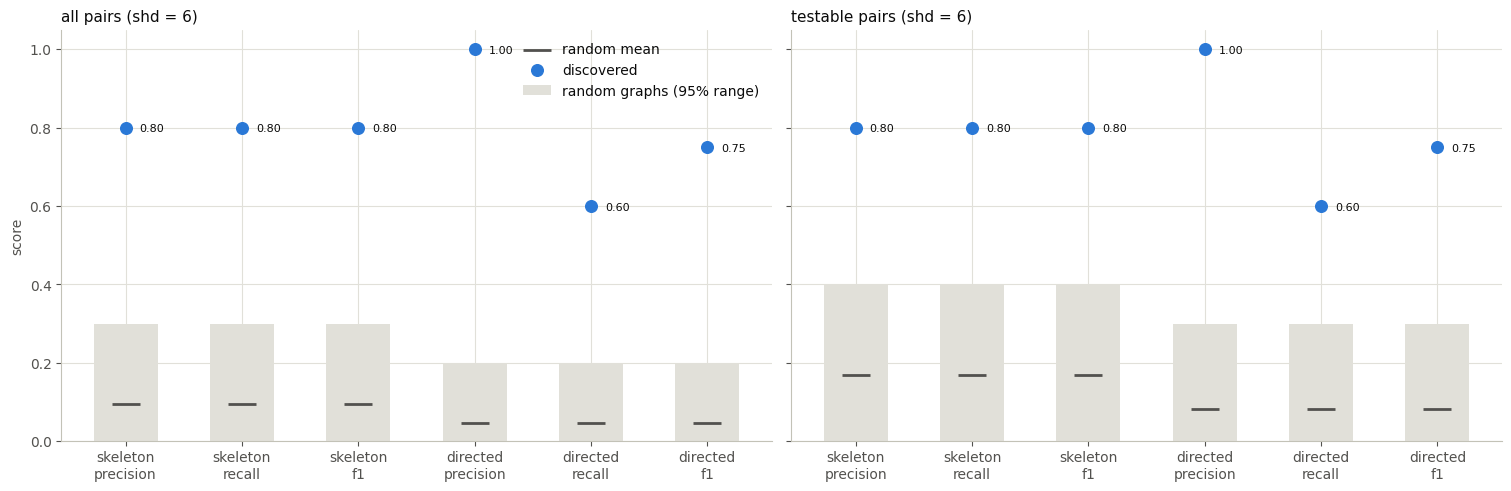

In [7]:
# figure 3: discovered metrics vs the distribution of random graphs
names = ['skeleton_precision', 'skeleton_recall', 'skeleton_f1', 'directed_precision', 'directed_recall', 'directed_f1']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True, layout='constrained')
for ax, scope in zip(axes, ['all pairs', 'testable pairs']):
    draws = reference_draws[scope]
    found = metric_table[(metric_table.graph == 'discovered') & (metric_table.scope == scope)].iloc[0]
    x = np.arange(len(names))
    low, high = draws[names].quantile(0.025).to_numpy(), draws[names].quantile(0.975).to_numpy()
    ax.bar(x, high - low, bottom=low, width=0.55, color=ev.INK['grid'], label='random graphs (95% range)')
    ax.scatter(x, draws[names].mean(), marker='_', s=400, color=ev.INK['secondary'], label='random mean', zorder=3)
    ax.scatter(x, found[names].astype(float), s=70, color=ev.COLORS[0], zorder=4, label='discovered')
    for xi, v in zip(x, found[names].astype(float)):
        ax.annotate(f'{v:.2f}', (xi, v), textcoords='offset points', xytext=(10, -3), fontsize=8)
    ax.set_xticks(x, [n.replace('_', '\n') for n in names])
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{scope} (shd = {found.shd:.0f})')
axes[0].set_ylabel('score')
axes[0].legend(loc='upper right')
ev.save_figure(fig, f'04_{SUBSYSTEM}_metrics_vs_random')
plt.show()

## 3. Lagged and contemporaneous evidence separately

Each discovered edge is labelled by the evidence behind it: only lagged links, only lag-0 links, or both. The expert graph has no lags, so only precision can be split this way.

In [8]:
# precision by evidence type
def basis_of(lags):
    lags = json.loads(lags) if isinstance(lags, str) else lags
    if not lags:
        return 'none'
    if set(lags) == {0}:
        return 'lag 0 only'
    return 'lagged only' if 0 not in lags else 'lagged and lag 0'

comparison_found = comparison[comparison.outcome != 'missed'].copy()
comparison_found['evidence'] = comparison_found.lags_steps.map(basis_of)
comparison_found['adjacency_correct'] = comparison_found.outcome != 'extra'
comparison_found['direction_correct'] = comparison_found.outcome == 'correct direction'
by_basis = comparison_found.groupby('evidence').agg(
    edges=('outcome', 'size'),
    skeleton_precision=('adjacency_correct', 'mean'),
    directed_precision=('direction_correct', 'mean'),
).reset_index()
ev.save_table(by_basis, f'04_{SUBSYSTEM}_precision_by_evidence')
by_basis.round(3)

,evidence,edges,skeleton_precision,directed_precision
0,lag 0 only,6,0.667,0.333
1,lagged and lag 0,1,1.000,1.000
2,lagged only,3,1.000,1.000


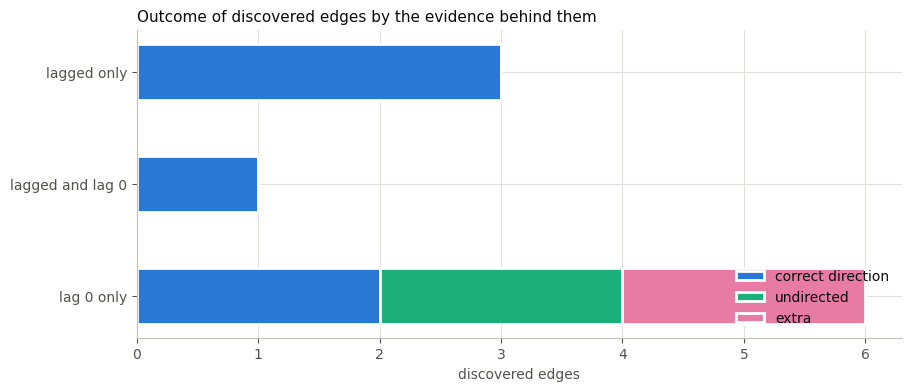

In [9]:
# figure 4: outcome of discovered edges by evidence type
counts = comparison_found.groupby(['evidence', 'outcome']).size().unstack(fill_value=0)
order = [o for o in outcome_style if o in counts.columns]
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
left = np.zeros(len(counts))
for o in order:
    ax.barh(counts.index, counts[o], left=left, color=outcome_style[o][0], height=0.5, label=o,
            edgecolor=ev.INK['surface'], linewidth=2)
    left += counts[o].to_numpy()
ax.set_xlabel('discovered edges')
ax.set_title('Outcome of discovered edges by the evidence behind them')
ax.legend(loc='lower right')
ev.save_figure(fig, f'04_{SUBSYSTEM}_outcome_by_evidence')
plt.show()

## 4. Leave-one-scenario-out graphs and sensitivity variants

These graphs are evaluated for reporting only; none of them is selected by its score.

In [10]:
# metrics of the leave-one-scenario-out graphs and of the sensitivity variants
rows = []
for gid, graph in graphs.items():
    rows.append({'group': 'leave one scenario out' if gid != 'discovered' else 'primary', 'graph': gid,
                 **ge.compare_graphs(graph, expert)})
variant_edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_sensitivity_edges.csv')
for name, g in variant_edges.groupby('variant', sort=False):
    rows.append({'group': 'sensitivity', 'graph': name, **ge.compare_graphs(cd.edges_to_graph(g, NODES), expert)})
variant_metrics = pd.DataFrame(rows)
ev.save_table(variant_metrics, f'04_{SUBSYSTEM}_variant_metrics')
variant_metrics[['group', 'graph', 'n_pred_edges', 'skeleton_f1', 'directed_f1', 'shd', 'orientation_accuracy']].round(3)

,group,graph,n_pred_edges,skeleton_f1,directed_f1,shd,orientation_accuracy
0,primary,discovered,10,0.800,0.750,6,1.000
1,leave one scenario out,discovered_without_exp_22,7,0.706,0.750,5,1.000
2,leave one scenario out,discovered_without_exp_27,9,0.737,0.667,7,1.000
3,leave one scenario out,discovered_without_exp_28,9,0.737,0.667,7,1.000
4,leave one scenario out,discovered_without_exp_35,9,0.842,0.750,5,1.000
5,sensitivity,primary,10,0.800,0.750,6,1.000
6,sensitivity,grid 1 s,12,0.727,0.700,8,1.000
7,sensitivity,tau_max 5 s,10,0.800,0.750,6,1.000
8,sensitivity,tau_max 20 s,10,0.800,0.706,6,0.857
9,sensitivity,alpha 0.001,9,0.737,0.667,7,1.000


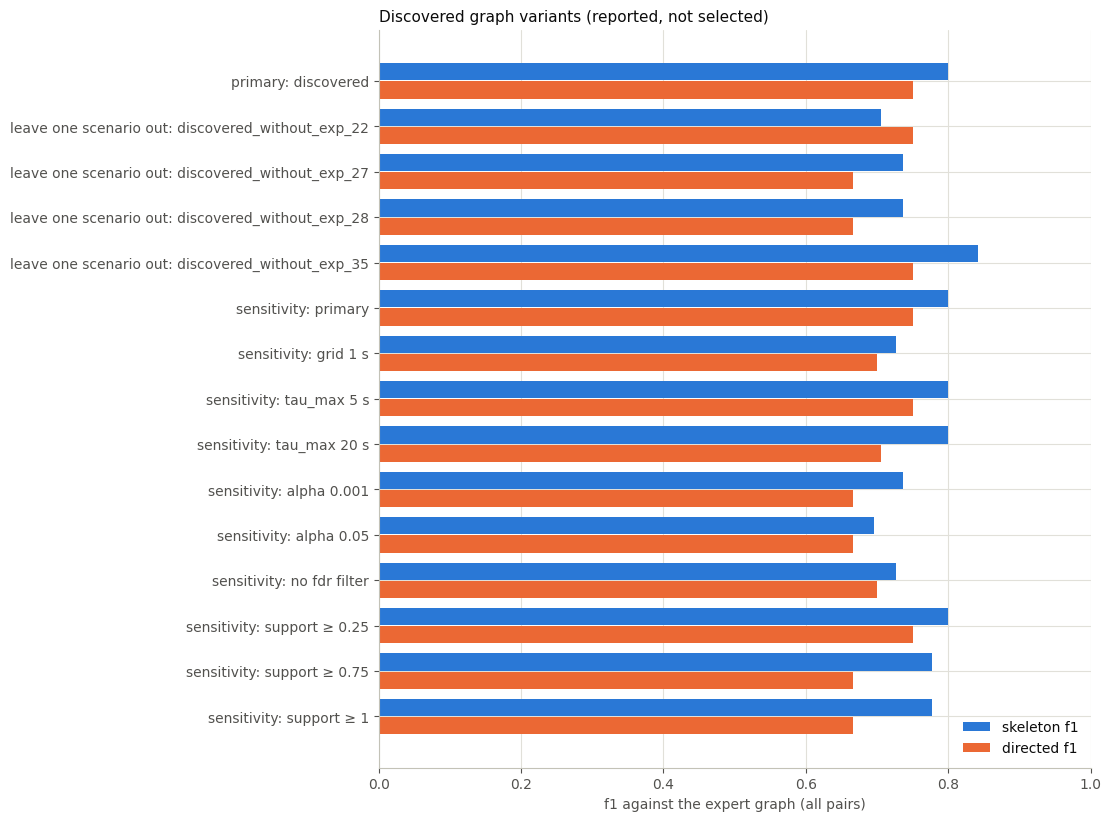

In [11]:
# figure 5: skeleton and directed f1 for every graph variant
fig, ax = plt.subplots(figsize=(11, 0.42 * len(variant_metrics) + 1.8), layout='constrained')
y = np.arange(len(variant_metrics))
ax.barh(y - 0.2, variant_metrics.skeleton_f1, height=0.38, color=ev.COLORS[0], label='skeleton f1')
ax.barh(y + 0.2, variant_metrics.directed_f1, height=0.38, color=ev.COLORS[1], label='directed f1')
ax.set_yticks(y, [f'{g}: {n}' for g, n in zip(variant_metrics.group, variant_metrics.graph)])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('f1 against the expert graph (all pairs)')
ax.set_title('Discovered graph variants (reported, not selected)')
ax.legend(loc='lower right')
ev.save_figure(fig, f'04_{SUBSYSTEM}_variant_f1')
plt.show()

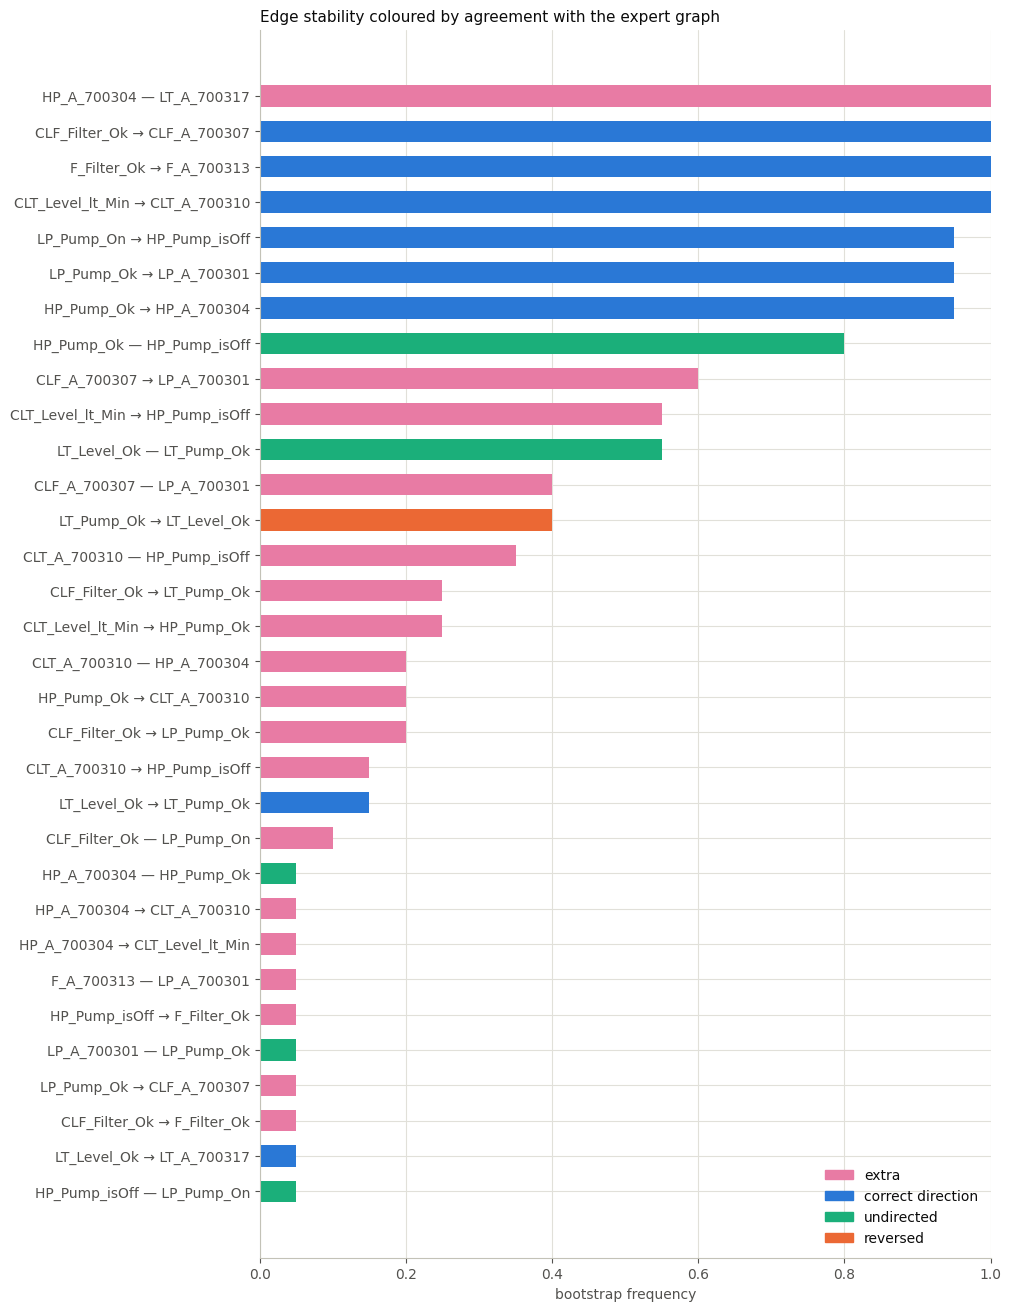

,size,mean
outcome,,
correct direction,8,0.76
extra,18,0.25
reversed,1,0.40
undirected,5,0.30


In [12]:
# figure 6: are stable edges more often correct?
stability = pd.read_csv(tables / f'03_{SUBSYSTEM}_bootstrap_stability.csv')
def edge_outcome(edge):
    if ' → ' in edge:
        a, b = edge.split(' → ')
        if expert.has_edge(a, b):
            return 'correct direction'
        return 'reversed' if expert.has_edge(b, a) else 'extra'
    a, b = edge.split(' — ')
    return 'undirected' if expert.has_edge(a, b) or expert.has_edge(b, a) else 'extra'
stability['outcome'] = stability.edge.map(edge_outcome)
fig, ax = plt.subplots(figsize=(10, 0.35 * len(stability) + 1.8), layout='constrained')
ax.barh(stability.edge, stability.bootstrap_frequency, color=[outcome_style[o][0] for o in stability.outcome], height=0.6)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('bootstrap frequency')
ax.set_title('Edge stability coloured by agreement with the expert graph')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=outcome_style[o][0], label=o) for o in stability.outcome.unique()],
          loc='lower right')
ev.save_figure(fig, f'04_{SUBSYSTEM}_stability_vs_correctness')
plt.show()
stability.groupby('outcome').bootstrap_frequency.agg(['size', 'mean']).round(2)

## 5. Findings

- **Agreement with the expert graph** (all pairs; every expert edge is testable, so the testable-pair scores are identical):

  | Metric | Discovered | Random graph, same size (mean) |
  |---|---|---|
  | Skeleton precision / recall / F1 | 0.80 / 0.80 / 0.80 | 0.09 |
  | Directed precision / recall / F1 | 1.00 / 0.60 / 0.75 | 0.05 |
  | SHD | 6 | 18.6 |
  | Orientation accuracy | 1.00 | 0.50 |

- **Every oriented edge has the right direction.** The 6 correct edges are the 5 *component → its own alarm* edges and `LP_Pump_On → HP_Pump_isOff`.
  - `HP_Pump_Ok — HP_Pump_isOff` and `LT_Level_Ok — LT_Pump_Ok` are found but stay undirected. Their changes are logged within one grid step, sometimes effect first.
  - **Missed:** `LT_Level_Ok → LT_A_700317` and `LP_Pump_Ok → LP_Pump_On`.
  - **Extra:** two alarm–alarm links (`HP_A_700304 — LT_A_700317`, `CLF_A_700307 — LP_A_700301`). Alarms of a multi-cause scenario fire together, which looks like dependence once their common causes are not in the conditioning set.
- **Evidence type:**
  - Every *lagged* edge is correct (precision 1.00).
  - Lag-0-only edges reach skeleton precision 0.67 and directed precision 0.33.
  - This is the batched-timestamp problem of the EDA, measured: the temporal information is reliable where it exists, and contemporaneous evidence is where the errors are.
- **Stability predicts correctness.** Correctly oriented edges have a mean bootstrap frequency of 0.76; extra edges 0.25.
- **Variants** (reported, not selected): directed F1 between 0.67 and 0.75 for all leave-one-out graphs and sensitivity settings, so the conclusions do not hinge on one setting.
- *Thesis note:* "agreement" here means agreement with expert knowledge. The two extra alarm–alarm links may well be real statistical dependences without being causal. The graph cannot settle that; the downstream tasks in notebooks 06–09 show whether it matters.